# FIFA 22 Player Market Value Prediction

## DS330 Project Part 1

This project develops and compares models for predicting the market value of FIFA 22 players. The analysis uses player attributes to estimate `value_eur`, expressed in millions of euros (€M), and follows a controlled one-factor-at-a-time (OFAT) tuning strategy.

**Models compared**
- Linear Regression baseline
- Deep neural network baseline
- Hyperparameter-tuned deep neural networks

**Evaluation framework**
- 70% training, 15% validation, and 15% test split
- Training-set-only standardization to prevent data leakage
- Validation MSE for model selection
- Held-out test MSE and RMSE for final reporting

### Required Libraries

Import the data-processing, machine-learning, PyTorch, and plotting tools used throughout the notebook.

In [1]:
import pandas as pd 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch 
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
from sklearn.metrics import mean_squared_error
import time
import matplotlib.pyplot as plt

## 1. Dataset Loading and Initial Inspection

We begin by loading the FIFA 22 player dataset directly from the project repository. The raw dataset contains 19,239 player records and 110 columns. Initial inspection helps identify target availability, missing values, and features that should be removed or transformed before modeling.

In [2]:
url = 'https://raw.githubusercontent.com/ab8d-DS/dl_project_p1/refs/heads/main/players_22.csv'
df_original = pd.read_csv(url, low_memory=False)


**Preview:** The first few rows confirm the available schema and representative values before cleaning.

In [3]:
df_original.head(3)

,sofifa_id,player_url,short_name,long_name,player_positions,overall,potential,value_eur,wage_eur,age,...,lcb,cb,rcb,rb,gk,player_face_url,club_logo_url,club_flag_url,nation_logo_url,nation_flag_url
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,"RW, ST, CF",93,93,78000000.0,320000.0,34,...,50+3,50+3,50+3,61+3,19+3,https://cdn.sofifa.net/players/158/023/22_120.png,https://cdn.sofifa.net/teams/73/60.png,https://cdn.sofifa.net/flags/fr.png,https://cdn.sofifa.net/teams/1369/60.png,https://cdn.sofifa.net/flags/ar.png
1,188545,https://sofifa.com/player/188545/robert-lewand...,R. Lewandowski,Robert Lewandowski,ST,92,92,119500000.0,270000.0,32,...,60+3,60+3,60+3,61+3,19+3,https://cdn.sofifa.net/players/188/545/22_120.png,https://cdn.sofifa.net/teams/21/60.png,https://cdn.sofifa.net/flags/de.png,https://cdn.sofifa.net/teams/1353/60.png,https://cdn.sofifa.net/flags/pl.png
2,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,"ST, LW",91,91,45000000.0,270000.0,36,...,53+3,53+3,53+3,60+3,20+3,https://cdn.sofifa.net/players/020/801/22_120.png,https://cdn.sofifa.net/teams/11/60.png,https://cdn.sofifa.net/flags/gb-eng.png,https://cdn.sofifa.net/teams/1354/60.png,https://cdn.sofifa.net/flags/pt.png


**Data-quality check:** Identify which columns contain missing values and how extensive those omissions are.

In [4]:
df_original.isna().sum()[df_original.isna().sum() > 0]

value_eur                       74
wage_eur                        61
club_team_id                    61
club_name                       61
league_name                     61
league_level                    61
club_position                   61
club_jersey_number              61
club_loaned_from             18137
club_joined                   1163
club_contract_valid_until       61
nation_team_id               18480
nation_position              18480
nation_jersey_number         18480
release_clause_eur            1176
player_tags                  17798
player_traits                 9841
pace                          2132
shooting                      2132
passing                       2132
dribbling                     2132
defending                     2132
physic                        2132
goalkeeping_speed            17107
club_logo_url                   61
club_flag_url                   61
nation_logo_url              18480
dtype: int64

### 1.1 Missing-Value Pattern

The missing values are largely position-dependent:

- Goalkeepers do not have outfield summary attributes (`pace`, `shooting`, `passing`, `dribbling`, `defending`, and `physic`).
- Outfield players do not have the goalkeeper-only `goalkeeping_speed` attribute.

These columns are redundant with more detailed position-specific attributes, so they can be removed without discarding player records.

**Position-specific missing values:** Confirm the relationship between goalkeepers and outfield summary attributes.

In [5]:
outfield_summary_stats = ['pace', 'shooting', 'passing','dribbling','defending','physic']
print(f'Num of Goalkeepers: {len(df_original[df_original['player_positions'] == 'GK'])}')
print(f'NaN Cols:\n{df_original[df_original['player_positions'] == 'GK'].loc[:,outfield_summary_stats].isna().sum()}')

Num of Goalkeepers: 2132
NaN Cols:
pace         2132
shooting     2132
passing      2132
dribbling    2132
defending    2132
physic       2132
dtype: int64


## 2. Data Cleaning and Feature Engineering

The raw schema contains identifiers, URLs, text fields, and several attributes that may be unsuitable or unsafe for the prediction task. We also remove fields that could leak financial or highly related information about a player's market value.

The cleaning process produces a numeric feature matrix while preserving meaningful football attributes for the regression task.

### 2.1 Feature-Removal Policy

Define the columns to remove because they are identifiers, URLs, sparse text fields, unrelated metadata, or potential leakage sources.

In [ ]:
cols_to_drop = [
    # 1. Financial Leakage(2)
    "wage_eur", "release_clause_eur",

    # 2. IDs, Names, Image URLs & High-Cardinality Text (15)
    "sofifa_id", "player_url", "short_name", "long_name",
    "player_face_url", "club_logo_url", "club_flag_url",
    "nation_logo_url", "nation_flag_url", "real_face",
    "player_tags", "player_traits", "club_name",
    "league_name", "nationality_name",

    # 3. Dates, Shirt Numbers & Sparse/Arbitrary Columns (13)
    "dob", "club_team_id", "club_position", "club_jersey_number",
    "club_loaned_from", "club_joined", "club_contract_valid_until",
    "nationality_id", "nation_team_id", "nation_position",
    "nation_jersey_number", "body_type", "work_rate",

    # 4. Positional Rating Strings (27)
    "ls", "st", "rs", "lw", "lf", "cf", "rf", "rw",
    "lam", "cam", "ram", "lm", "lcm", "cm", "rcm", "rm",
    "lwb", "ldm", "cdm", "rdm", "rwb", "lb", "lcb", "cb", "rcb", "rb", "gk",

    # 5. Mutual-NaN Summary Stats (7)
    "pace", "shooting", "passing", "dribbling", "defending", "physic",
    "goalkeeping_speed"
]

**Apply cleaning:** Remove the excluded fields from the working DataFrame.

In [7]:
df = df_original.drop(cols_to_drop, axis = 1)
df.head()

,player_positions,overall,potential,value_eur,age,height_cm,weight_kg,league_level,preferred_foot,weak_foot,...,mentality_penalties,mentality_composure,defending_marking_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes
0,"RW, ST, CF",93,93,78000000.0,34,170,72,1.0,Left,4,...,75,96,20,35,24,6,11,15,14,8
1,ST,92,92,119500000.0,32,185,81,1.0,Right,4,...,90,88,35,42,19,15,6,12,8,10
2,"ST, LW",91,91,45000000.0,36,187,83,1.0,Right,4,...,88,95,24,32,24,7,11,15,14,11
3,"LW, CAM",91,91,129000000.0,29,175,68,1.0,Right,5,...,93,93,35,32,29,9,9,15,15,11
4,"CM, CAM",91,91,125500000.0,30,181,70,1.0,Right,5,...,83,89,68,65,53,15,13,5,10,13


### 2.2 Domain-Based Features

Three compact features are added from the existing categorical information:

- `is_top5_league`: identifies players in one of Europe's top five leagues
- `preferred_foot_right`: encodes whether the preferred foot is right
- `num_of_positions`: records the number of positions a player can occupy

The original target and league-level columns are required for this analysis, so records with missing values in these fields are removed. Market values are converted from euros to millions of euros so that reported errors have an intuitive scale.

**Create domain features:** Encode league status, preferred foot, and positional flexibility.

In [8]:
top_5_leagues = ['French Ligue 1', 'German 1. Bundesliga', 'English Premier League', 'Spain Primera Division', 'Italian Serie A']
df['is_top5_league'] = df_original['league_name'].isin(top_5_leagues).astype(int)
df['preferred_foot_right'] = (df['preferred_foot'] == 'Right').astype(int)
df['num_of_positions'] = df['player_positions'].str.split(',').str.len()

**2.3 Clean the feature frame:** Remove the engineered categorical fields and incomplete target or league records.

In [9]:
df = df.drop(['preferred_foot','player_positions'], axis = 1)
df = df.dropna(subset=["value_eur", "league_level"]).reset_index(drop=True)
df.head()

,overall,potential,value_eur,age,height_cm,weight_kg,league_level,weak_foot,skill_moves,international_reputation,...,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,is_top5_league,preferred_foot_right,num_of_positions
0,93,93,78000000.0,34,170,72,1.0,4,4,5,...,35,24,6,11,15,14,8,1,0,3
1,92,92,119500000.0,32,185,81,1.0,4,4,5,...,42,19,15,6,12,8,10,1,1,1
2,91,91,45000000.0,36,187,83,1.0,4,5,5,...,32,24,7,11,15,14,11,1,1,2
3,91,91,129000000.0,29,175,68,1.0,5,5,5,...,32,29,9,9,15,15,11,1,1,2
4,91,91,125500000.0,30,181,70,1.0,5,4,4,...,65,53,15,13,5,10,13,1,1,2


**2.4 Rescale the target:** Convert market value from euros to millions of euros.

In [10]:
df['value_eur'] = df['value_eur'] / 1000000

## 3. Train, Validation, and Test Preparation

To obtain a reliable estimate of generalization performance, the data is partitioned into:

- **Training set:** 70% — used to fit models
- **Validation set:** 15% — used for hyperparameter selection
- **Test set:** 15% — evaluated only after the champion model is selected

A fixed random seed is used for reproducibility. Numerical features and the target are standardized using statistics computed only from the training data, preventing validation and test information from entering preprocessing.

**Separate features and target:** Store player attributes in `X` and market value in `y`.

In [11]:
X = df.drop('value_eur', axis = 1)
y = df[['value_eur']]

**Create reproducible partitions:** Divide the dataset into training, validation, and test sets.

In [12]:
X_full_train, X_test, y_full_train, y_test = train_test_split(X,y, test_size=0.15, random_state=42)
X_train,X_val,y_train,y_val = train_test_split(X_full_train,y_full_train,test_size= 0.17647 ,random_state=42)

**Verify split dimensions:** Report the number of rows and columns in each partition.

In [13]:
print(f'Shape of:\nX train: {X_train.shape} | X val: {X_val.shape}, X test: {X_test.shape}')
print(f'y train: {y_train.shape}  | y val: {y_val.shape}, y test: {y_test.shape}')

Shape of:
X train: (13415, 46) | X val: (2875, 46), X test: (2875, 46)
y train: (13415, 1)  | y val: (2875, 1), y test: (2875, 1)


**Standardize features:** Fit the scaler on training data only, then transform all partitions.

In [14]:
Scaler_X = StandardScaler()

X_train_scaled = Scaler_X.fit_transform(X_train)
X_val_scaled = Scaler_X.transform(X_val)
X_test_scaled = Scaler_X.transform(X_test)

**Standardize the target:** Fit a separate scaler on `y_train` and apply it consistently to all target partitions.

In [15]:
Scaler_y = StandardScaler()

y_train_scaled = Scaler_y.fit_transform(y_train)
y_val_scaled = Scaler_y.transform(y_val)
y_test_scaled = Scaler_y.transform(y_test)

### 3.1 PyTorch Dataset and Batching

The standardized arrays are converted to 32-bit floating-point tensors. Each input sample contains 46 features, while each target is represented as a one-dimensional value. `DataLoader` instances create mini-batches for training and ensure that validation and test data are evaluated without shuffling.

**Create PyTorch tensors:** Convert both features and targets to `float32` tensors.

In [16]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)

**Check tensor shapes:** Confirm the dimensions and data types supplied to the network.

In [17]:
print("X_train:", X_train_tensor.shape, X_train_tensor.dtype)
print("y_train:", y_train_tensor.shape, y_train_tensor.dtype)

X_train: torch.Size([13415, 46]) torch.float32
y_train: torch.Size([13415, 1]) torch.float32


**Build paired datasets:** Associate each input tensor with its corresponding target tensor.

In [18]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

**Configure mini-batching:** Use shuffled training batches and fixed, unshuffled validation/test batches.

In [19]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

## 4. Baseline Models

Two baseline models establish reference performance before hyperparameter tuning:

- **Linear Regression:** A single linear layer with 46 inputs and one output. This provides a transparent benchmark for a direct, linear relationship.
- **Baseline DNN:** A three-layer network with `[64, 64, 64]` ReLU hidden units. Linear layers use He initialization to support stable ReLU training.

Both models use the standardized target and a mini-batch training setup, making their results directly comparable with the tuned experiments.

### 4.1 Weight Initialization Helper

He initialize linear-layer weights for ReLU activations and set biases to zero.

In [20]:
def weights_init(layer):
    if isinstance(layer, nn.Linear):
        nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
        nn.init.zeros_(layer.bias)

### 4.2 Baseline Training Procedure

Both baselines are trained for 30 epochs using stochastic gradient descent, a learning rate of `0.01`, mini-batches of 64 samples, and mean squared error loss. The validation MSE is recorded after each epoch so convergence behavior can be inspected.

### 4.3 Reusable Training and Evaluation Helpers

The helper functions standardize MSE measurement and centralize the training loop used for baseline and OFAT runs.

In [21]:
def mse_original(model, X, y_true, scaler_y):
    model.eval()
    with torch.no_grad():
        preds = model(X).numpy()
    if not np.isfinite(preds).all():
        return np.nan
    return mean_squared_error(y_true, scaler_y.inverse_transform(preds))

def train_model(model, train_loader, criterion, optimizer, epochs=30):
    history = {"train_mse": [], "val_mse": []}
    for epoch in range(epochs):
        model.train()
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
        history["train_mse"].append(mse_original(model, X_train_tensor, y_train, Scaler_y))
        history["val_mse"].append(mse_original(model, X_val_tensor, y_val, Scaler_y))
    return history

### 4.4 Baseline Evaluation

For evaluation, the trained model is switched to inference mode and predictions are converted back from standardized units to euros, then expressed in millions. Training and validation MSE are reported in **€M²** to make model performance comparable on the original target scale.

## 5. One-Factor-at-a-Time (OFAT) Hyperparameter Tuning

The OFAT protocol changes one design factor at a time while retaining the baseline configuration for all other factors. This isolates the contribution of each candidate setting and makes the experimental results easier to interpret.

The shared experimental runner uses a fixed seed, so differences within a topic primarily reflect the factor being tested rather than a change in data or initialization.

### 5.1 Network-Construction Helper

Construct a configurable MLP and apply He initialization when at least one hidden layer is present.

In [22]:
def build_dnn(hidden_layers, input_dim=46, output_dim=1):
    layers = []
    in_dim = input_dim
    for h in hidden_layers:
        layers.append(nn.Linear(in_dim, h))
        layers.append(nn.ReLU())
        in_dim = h
    layers.append(nn.Linear(in_dim, output_dim))
    net = nn.Sequential(*layers)
    if len(hidden_layers) > 0:
        net.apply(weights_init)
    return net

### 5.2 OFAT Experimental Runner

This runner builds a fresh model, creates the requested optimizer and loss, executes training, and stores configuration, metrics, history, and runtime.

In [23]:
BASE = dict(hidden_layers=[64, 64, 64], lr=0.01, optimizer_name="SGD", momentum=0.0,
            nesterov=False, batch_size=64, loss_name="MSE", huber_delta=1.0, num_epochs=30)

def run_ofat_experiment(
    topic,
    run_label,
    hidden_layers=[64, 64, 64],
    lr=0.01,
    optimizer_name="SGD",
    momentum=0.0,
    nesterov=False,
    batch_size=64,
    loss_name="MSE",
    huber_delta=1.0,
    num_epochs=30,
    seed=42
):
    config = dict(hidden_layers=list(hidden_layers), lr=lr, optimizer_name=optimizer_name,
                  momentum=momentum, nesterov=nesterov, batch_size=batch_size,
                  loss_name=loss_name, huber_delta=huber_delta, num_epochs=num_epochs)
    
    changed = [f"{k}={v}" for k, v in config.items() if v != BASE[k]]
    setting_changed = ", ".join(changed) if changed else "none (baseline)"

    torch.manual_seed(seed)
    np.random.seed(seed)

    loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    model = build_dnn(hidden_layers)
    num_params = sum(p.numel() for p in model.parameters())

    if loss_name == "MSE":
        criterion = nn.MSELoss()
    elif loss_name == "L1":
        criterion = nn.L1Loss()
    elif loss_name == "Huber":
        criterion = nn.HuberLoss(delta=huber_delta)

    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum, nesterov=nesterov)
    elif optimizer_name == "Adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    elif optimizer_name == "RMSprop":
        optimizer = torch.optim.RMSprop(model.parameters(), lr=lr)

    start_time = time.time()
    history = train_model(model, loader, criterion, optimizer, epochs=num_epochs)
    runtime_sec = time.time() - start_time

    train_mse, val_mse = history["train_mse"][-1], history["val_mse"][-1]
    status = "Diverged (NaN)" if np.isnan(val_mse) else "Converged"

    return {
        "Topic": topic,
        "Run": run_label,
        "Setting_Changed": setting_changed,
        "Architecture": str(hidden_layers),
        "Params": num_params,
        "Optimizer": optimizer_name if optimizer_name != "SGD" else f"SGD(m={momentum},nest={nesterov})",
        "LR": lr,
        "Batch_Size": batch_size,
        "Loss": loss_name if loss_name != "Huber" else f"Huber(d={huber_delta})",
        "Train_MSE_€M2": train_mse,
        "Val_MSE_€M2": val_mse,
        "Runtime_s": round(runtime_sec, 2),
        "Status": status,
        "history": history,
        "config": config,
        "model": model
    }

**Run baseline comparisons:** Train the linear and baseline deep networks using the standard configuration.

In [24]:
all_results = []

lin_res = run_ofat_experiment(topic="Baseline", run_label="Linear Regression", hidden_layers=[])
dnn_res = run_ofat_experiment(topic="Baseline", run_label="Baseline DNN [64,64,64]")

linear_model = lin_res["model"]
lin_train_mse, lin_val_mse = lin_res["Train_MSE_€M2"], lin_res["Val_MSE_€M2"]
dnn_train_mse, dnn_val_mse = dnn_res["Train_MSE_€M2"], dnn_res["Val_MSE_€M2"]

print(f"Linear Regression -> Train MSE: {lin_train_mse:.4f} €M² | Val MSE: {lin_val_mse:.4f} €M² | {lin_res['Runtime_s']}s")
print(f"Baseline DNN      -> Train MSE: {dnn_train_mse:.4f} €M² | Val MSE: {dnn_val_mse:.4f} €M² | {dnn_res['Runtime_s']}s")

Linear Regression -> Train MSE: 25.0035 €M² | Val MSE: 26.3289 €M² | 3.03s
Baseline DNN      -> Train MSE: 1.6868 €M² | Val MSE: 4.4052 €M² | 4.87s


**Plotting utility:** Visualize training and validation MSE for each OFAT topic.

In [25]:
def plot_topic(topic):
    runs = [r for r in all_results if r["Topic"] == topic]
    diverged = [r["Run"] for r in runs if r["Status"] != "Converged"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, key, name in zip(axes, ["train_mse", "val_mse"], ["Training MSE", "Validation MSE"]):
        for r in runs:
            curve = np.array(r["history"][key], dtype=float)
            if np.isnan(curve).all():
                continue
            ax.plot(np.arange(1, len(curve) + 1), curve, linewidth=1.6, label=r["Run"])
        base = np.array(dnn_res["history"][key], dtype=float)
        ax.plot(np.arange(1, len(base) + 1), base, color="black", linewidth=2.4, label="Baseline DNN")
        ax.axhline(lin_res["history"][key][-1], color="gray", linestyle="--", label="Linear regression (final)")
        ax.set_yscale("log")
        ax.set_title(f"{name} per epoch")
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("MSE (€M², log scale)")
    axes[1].legend(fontsize=7, loc="upper right")
    note = f" | diverged (not drawn): {', '.join(diverged)}" if diverged else ""
    fig.suptitle(f"{topic}{note}", x=0.05, ha="left", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

### 5.3 Topic 1: Learning Rate

This experiment tests learning rates from `0.0001` to `0.5` while keeping the network, batch size, optimizer, and loss constant. Small values may learn too slowly, whereas excessively large values may cause unstable updates or numerical divergence.

**Run learning-rate experiments:** Train one network per candidate learning rate.

In [26]:
learning_rates = [0.0001, 0.001, 0.002, 0.005, 0.05, 0.1, 0.5]

for lr in learning_rates:
    res = run_ofat_experiment(
        topic="Topic 1: Learning Rate",
        run_label=f"lr={lr}",
        lr=lr
    )
    all_results.append(res)
    print(f"{res['Run']:12s} | Train MSE: {res['Train_MSE_€M2']:8.4f} €M² | Val MSE: {res['Val_MSE_€M2']:8.4f} €M² | {res['Status']}")

lr=0.0001    | Train MSE:  25.8289 €M² | Val MSE:  26.7495 €M² | Converged
lr=0.001     | Train MSE:   8.6612 €M² | Val MSE:  11.5269 €M² | Converged
lr=0.002     | Train MSE:   5.6766 €M² | Val MSE:   9.1512 €M² | Converged
lr=0.005     | Train MSE:   3.0042 €M² | Val MSE:   5.8561 €M² | Converged
lr=0.05      | Train MSE:      nan €M² | Val MSE:      nan €M² | Diverged (NaN)
lr=0.1       | Train MSE:      nan €M² | Val MSE:      nan €M² | Diverged (NaN)
lr=0.5       | Train MSE:      nan €M² | Val MSE:      nan €M² | Diverged (NaN)


**Compare learning curves:** Plot training and validation MSE for every learning-rate setting.

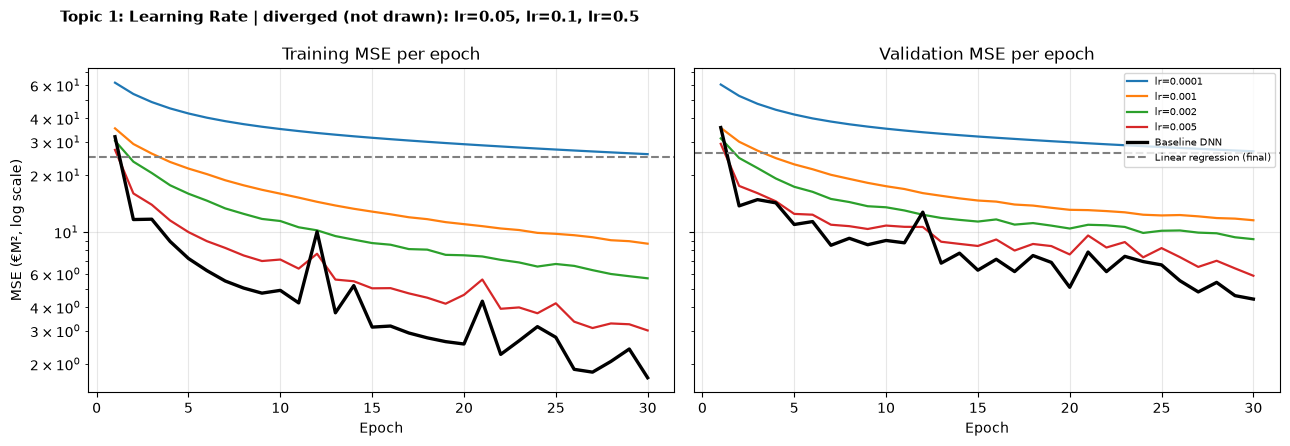

In [27]:
plot_topic("Topic 1: Learning Rate")

### 5.4 Topic 2: Optimizer

This topic compares vanilla SGD, momentum variants, Nesterov acceleration, Adam, and RMSprop. These optimizers differ in how they accumulate and adapt gradient updates, making them an important source of training stability and convergence speed.

**Run optimizer experiments:** Compare SGD variants with adaptive optimizers under the baseline architecture.

In [28]:
optimizer_configs = [
    {"label": "SGD+Mom(0.5, lr=0.01)",      "opt": "SGD",     "lr": 0.01,  "mom": 0.5,  "nest": False},
    {"label": "SGD+Mom(0.9, lr=0.01)",      "opt": "SGD",     "lr": 0.01,  "mom": 0.9,  "nest": False},
    {"label": "SGD+Mom(0.99, lr=0.01)",     "opt": "SGD",     "lr": 0.01,  "mom": 0.99, "nest": False},
    {"label": "SGD+Nesterov(0.9, lr=0.01)", "opt": "SGD",     "lr": 0.01,  "mom": 0.9,  "nest": True},
    {"label": "Adam(lr=0.001)",             "opt": "Adam",    "lr": 0.001, "mom": 0.0,  "nest": False},
    {"label": "Adam(lr=0.01)",              "opt": "Adam",    "lr": 0.01,  "mom": 0.0,  "nest": False},
    {"label": "RMSprop(lr=0.001)",          "opt": "RMSprop",  "lr": 0.001, "mom": 0.0,  "nest": False},
]

for ocfg in optimizer_configs:
    res = run_ofat_experiment(
        topic="Topic 2: Optimizer",
        run_label=ocfg["label"],
        optimizer_name=ocfg["opt"],
        lr=ocfg["lr"],
        momentum=ocfg["mom"],
        nesterov=ocfg["nest"]
    )
    all_results.append(res)
    print(f"{res['Run']:28s} | Train MSE: {res['Train_MSE_€M2']:8.4f} €M² | Val MSE: {res['Val_MSE_€M2']:8.4f} €M² | {res['Status']}")

SGD+Mom(0.5, lr=0.01)        | Train MSE:   0.9764 €M² | Val MSE:   3.5685 €M² | Converged
SGD+Mom(0.9, lr=0.01)        | Train MSE:   1.1616 €M² | Val MSE:   3.7782 €M² | Converged
SGD+Mom(0.99, lr=0.01)       | Train MSE:  60.1555 €M² | Val MSE:  56.9943 €M² | Converged
SGD+Nesterov(0.9, lr=0.01)   | Train MSE:   0.8732 €M² | Val MSE:   2.2430 €M² | Converged
Adam(lr=0.001)               | Train MSE:   1.4267 €M² | Val MSE:   4.6269 €M² | Converged
Adam(lr=0.01)                | Train MSE:   1.6116 €M² | Val MSE:   3.0848 €M² | Converged
RMSprop(lr=0.001)            | Train MSE:   0.6686 €M² | Val MSE:   3.1812 €M² | Converged


**Compare optimizer curves:** Review convergence behavior for all optimizer configurations.

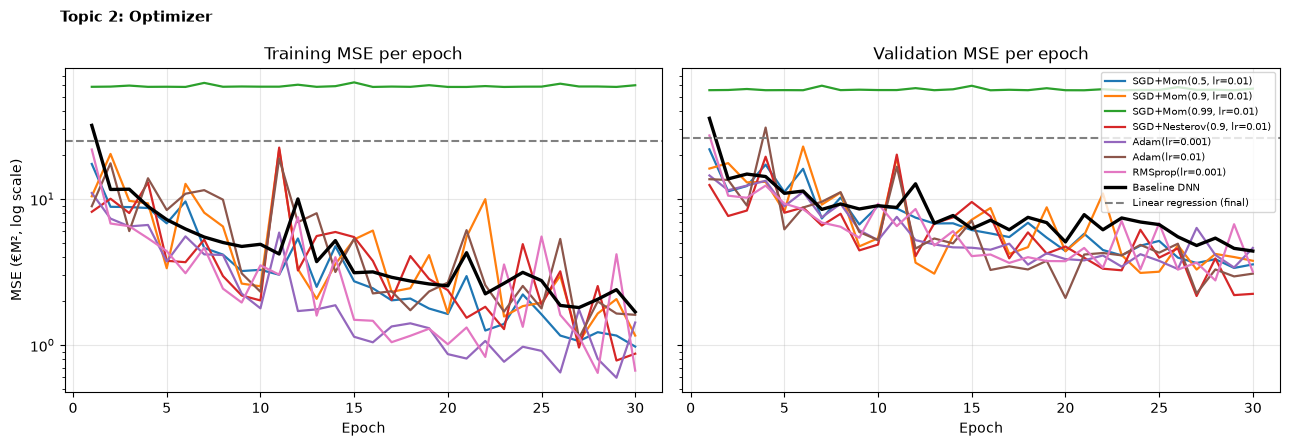

In [29]:
plot_topic("Topic 2: Optimizer")

### 5.5 Topic 3: Batch Size

This experiment varies the number of observations in each mini-batch. Smaller batches provide more frequent and noisier updates, while larger batches provide smoother gradients but fewer updates per epoch. Runtime is reported alongside MSE because batch size also affects computational cost.

**Run batch-size experiments:** Measure MSE and runtime across candidate mini-batch sizes.

In [30]:
batch_sizes = [8, 16, 32, 128, 256, 1024]

for bs in batch_sizes:
    res = run_ofat_experiment(
        topic="Topic 3: Batch Size",
        run_label=f"batch_size={bs}",
        batch_size=bs
    )
    all_results.append(res)
    print(f"{res['Run']:18s} | Train MSE: {res['Train_MSE_€M2']:8.4f} €M² | Val MSE: {res['Val_MSE_€M2']:8.4f} €M² | Time: {res['Runtime_s']:5.2f}s | {res['Status']}")

batch_size=8       | Train MSE:   2.2656 €M² | Val MSE:   4.0660 €M² | Time: 18.17s | Converged
batch_size=16      | Train MSE:   1.0929 €M² | Val MSE:   2.9844 €M² | Time: 10.15s | Converged
batch_size=32      | Train MSE:   2.1716 €M² | Val MSE:   4.1374 €M² | Time:  7.77s | Converged
batch_size=128     | Train MSE:   3.2037 €M² | Val MSE:   6.1368 €M² | Time:  4.32s | Converged
batch_size=256     | Train MSE:   5.1074 €M² | Val MSE:   8.3187 €M² | Time:  2.77s | Converged
batch_size=1024    | Train MSE:  10.9062 €M² | Val MSE:  13.6110 €M² | Time:  2.61s | Converged


**Compare batch-size curves:** Visualize the effect of batch size on training and validation error.

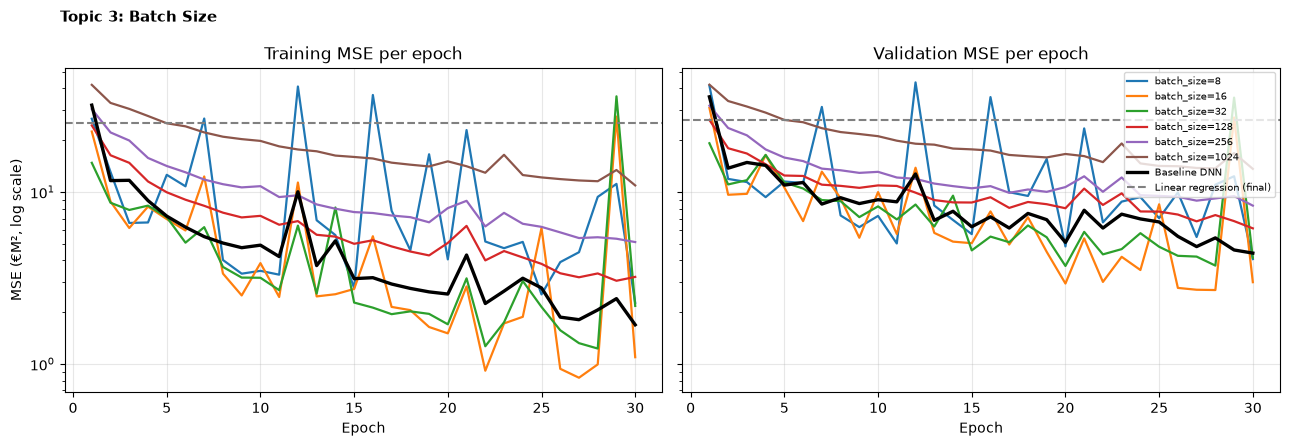

In [31]:
plot_topic("Topic 3: Batch Size") 

### 5.6 Topic 4: Network Depth and Width

This topic evaluates architectures ranging from a shallow 256-unit network to six hidden layers. Model capacity is compared with parameter count and validation MSE to assess whether additional depth or width improves generalization or introduces overfitting.

**Run architecture experiments:** Compare shallow, wider, and deeper networks under the OFAT protocol.

In [32]:
architectures = [
    {"label": "Shallow [256]",            "layers": [256]},
    {"label": "2-Layer [64, 64]",         "layers": [64, 64]},
    {"label": "4-Layer [64, 64, 64, 64]", "layers": [64, 64, 64, 64]},
    {"label": "Wide3 [128, 128, 128]",    "layers": [128, 128, 128]},
    {"label": "Wide3 [256, 256, 256]",    "layers": [256, 256, 256]},
    {"label": "Deep6 [32]x6",             "layers": [32, 32, 32, 32, 32, 32]},
    {"label": "Deep6 [64]x6",             "layers": [64, 64, 64, 64, 64, 64]},
]

for arch in architectures:
    res = run_ofat_experiment(
        topic="Topic 4: Depth & Width",
        run_label=arch["label"],
        hidden_layers=arch["layers"]
    )
    all_results.append(res)
    print(f"{res['Run']:26s} | Params: {res['Params']:6d} | Train MSE: {res['Train_MSE_€M2']:8.4f} €M² | Val MSE: {res['Val_MSE_€M2']:8.4f} €M² | {res['Status']}")

Shallow [256]              | Params:  12289 | Train MSE:   8.6616 €M² | Val MSE:  11.9592 €M² | Converged
2-Layer [64, 64]           | Params:   7233 | Train MSE:   1.8366 €M² | Val MSE:   5.2798 €M² | Converged
4-Layer [64, 64, 64, 64]   | Params:  15553 | Train MSE:   1.3836 €M² | Val MSE:   4.7270 €M² | Converged
Wide3 [128, 128, 128]      | Params:  39169 | Train MSE:   1.1631 €M² | Val MSE:   4.7044 €M² | Converged
Wide3 [256, 256, 256]      | Params: 143873 | Train MSE:   0.8396 €M² | Val MSE:   4.3923 €M² | Converged
Deep6 [32]x6               | Params:   6817 | Train MSE:   9.0334 €M² | Val MSE:  11.0436 €M² | Converged
Deep6 [64]x6               | Params:  23873 | Train MSE:   1.0743 €M² | Val MSE:   3.7400 €M² | Converged


**Compare architecture curves:** Inspect generalization behavior for each network depth and width.

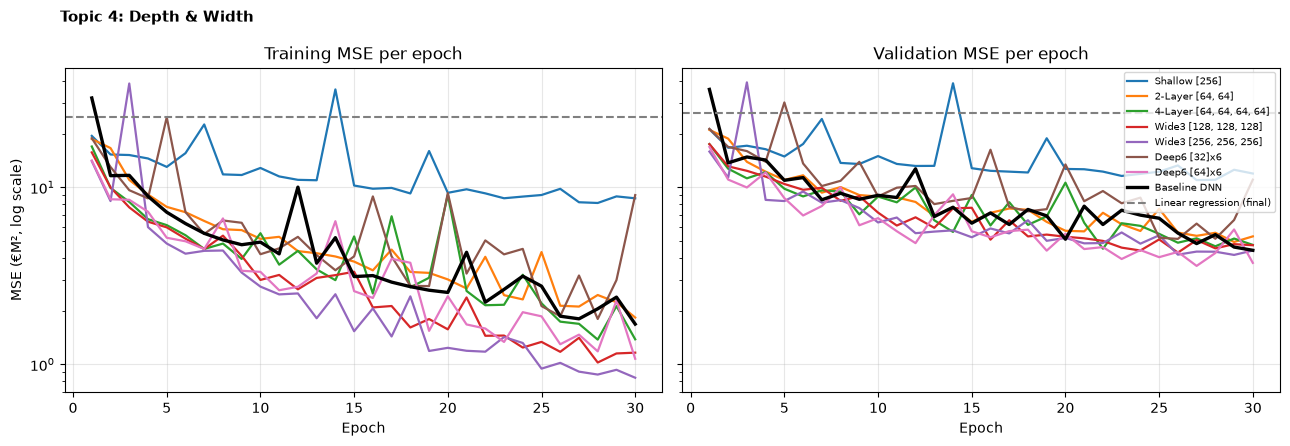

In [33]:
plot_topic("Topic 4: Depth & Width")

### 5.7 Topic 5: Loss Function

Standard MSE loss is compared with L1 loss and Huber loss. Huber loss combines an MSE-like penalty near zero with an absolute-error penalty farther from zero, making it less sensitive to unusually large player valuations.

**Run loss-function experiments:** Compare MSE, L1, and Huber losses while holding other settings fixed.

In [34]:
loss_configs = [
    {"label": "L1Loss",            "loss": "L1",    "delta": 1.0},
    {"label": "Huber(delta=0.5)",  "loss": "Huber", "delta": 0.5},
    {"label": "Huber(delta=1.0)",  "loss": "Huber", "delta": 1.0},
    {"label": "Huber(delta=2.0)",  "loss": "Huber", "delta": 2.0},
]

for lcfg in loss_configs:
    res = run_ofat_experiment(
        topic="Topic 5: Loss Function",
        run_label=lcfg["label"],
        loss_name=lcfg["loss"],
        huber_delta=lcfg["delta"]
    )
    all_results.append(res)
    print(f"{res['Run']:20s} | Train MSE: {res['Train_MSE_€M2']:8.4f} €M² | Val MSE: {res['Val_MSE_€M2']:8.4f} €M² | {res['Status']}")

L1Loss               | Train MSE:   4.7539 €M² | Val MSE:   6.4623 €M² | Converged
Huber(delta=0.5)     | Train MSE:   8.9665 €M² | Val MSE:   9.3824 €M² | Converged
Huber(delta=1.0)     | Train MSE:   6.0200 €M² | Val MSE:   7.3278 €M² | Converged
Huber(delta=2.0)     | Train MSE:   3.9286 €M² | Val MSE:   6.5667 €M² | Converged


**Compare loss curves:** Inspect training and validation performance for each loss configuration.

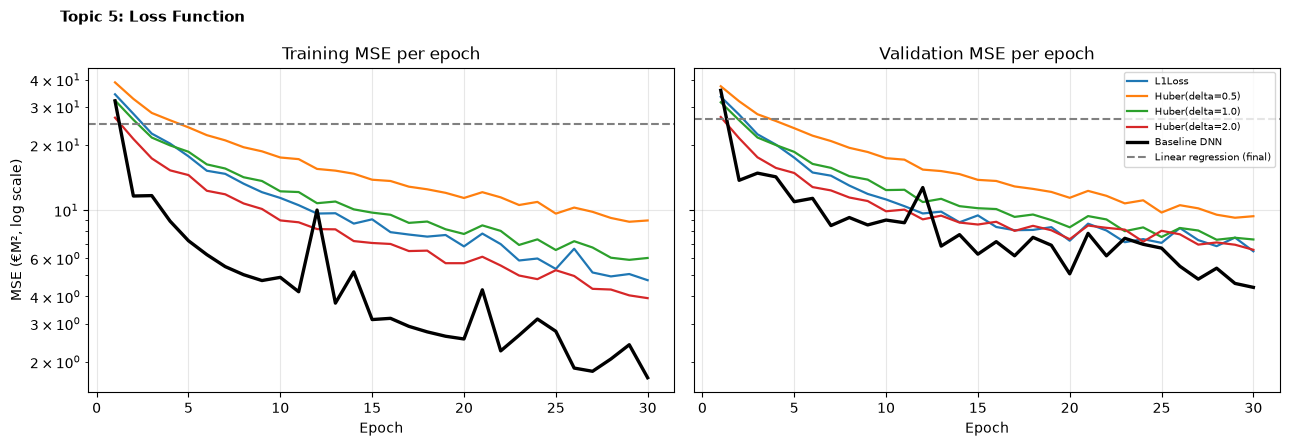

In [35]:
plot_topic("Topic 5: Loss Function")

### 5.8 Combined Hyperparameter Check

This experiment combines the strongest settings identified across the individual topics: a six-layer 64-unit architecture, SGD with Nesterov momentum, and a batch size of 16. The run checks whether these independently strong choices remain effective when combined. In the executed notebook, this combination diverged to `NaN` and was excluded from champion consideration.

**Train the combined candidate:** Use the strongest settings identified in the individual topic experiments.

In [36]:
combined_res = run_ofat_experiment(
    topic="Combined Check",
    run_label="Deep6[64]x6 + Nesterov(0.9) + BS=16 + MSE",
    hidden_layers=[64, 64, 64, 64, 64, 64],
    lr=0.01,
    optimizer_name="SGD",
    momentum=0.9,
    nesterov=True,
    batch_size=16,
    loss_name="MSE"
)

all_results.append(combined_res)
print(f"{combined_res['Run']} -> Train MSE: {combined_res['Train_MSE_€M2']:.4f} €M² | Val MSE: {combined_res['Val_MSE_€M2']:.4f} €M² | {combined_res['Status']}")

Deep6[64]x6 + Nesterov(0.9) + BS=16 + MSE -> Train MSE: nan €M² | Val MSE: nan €M² | Diverged (NaN)


## 6. Consolidated Experimental Results

All baseline and OFAT runs are combined into one table. Rows are sorted by validation MSE in €M² so the lowest-validation-error configuration can be identified quickly. Diverged or unstable runs remain visible rather than being omitted from the record.

**Create the result table:** Assemble all runs and sort them by validation MSE.

In [37]:
results_table = pd.DataFrame([lin_res, dnn_res] + all_results)
results_table = results_table.sort_values(by="Val_MSE_€M2").reset_index(drop=True)

display_cols = [c for c in results_table.columns if c not in ["history", "config", "model"]]
results_table[display_cols]

,Topic,Run,Setting_Changed,Architecture,Params,Optimizer,LR,Batch_Size,Loss,Train_MSE_€M2,Val_MSE_€M2,Runtime_s,Status
0,Topic 2: Optimizer,"SGD+Nesterov(0.9, lr=0.01)","momentum=0.9, nesterov=True","[64, 64, 64]",11393,"SGD(m=0.9,nest=True)",0.0100,64,MSE,0.873185,2.243018,6.02,Converged
1,Topic 3: Batch Size,batch_size=16,batch_size=16,"[64, 64, 64]",11393,"SGD(m=0.0,nest=False)",0.0100,16,MSE,1.092900,2.984382,10.15,Converged
2,Topic 2: Optimizer,Adam(lr=0.01),optimizer_name=Adam,"[64, 64, 64]",11393,Adam,0.0100,64,MSE,1.611567,3.084842,6.16,Converged
3,Topic 2: Optimizer,RMSprop(lr=0.001),"lr=0.001, optimizer_name=RMSprop","[64, 64, 64]",11393,RMSprop,0.0010,64,MSE,0.668598,3.181218,5.86,Converged
4,Topic 2: Optimizer,"SGD+Mom(0.5, lr=0.01)",momentum=0.5,"[64, 64, 64]",11393,"SGD(m=0.5,nest=False)",0.0100,64,MSE,0.976412,3.568465,5.82,Converged
5,Topic 4: Depth & Width,Deep6 [64]x6,"hidden_layers=[64, 64, 64, 64, 64, 64]","[64, 64, 64, 64, 64, 64]",23873,"SGD(m=0.0,nest=False)",0.0100,64,MSE,1.074325,3.739964,6.11,Converged
6,Topic 2: Optimizer,"SGD+Mom(0.9, lr=0.01)",momentum=0.9,"[64, 64, 64]",11393,"SGD(m=0.9,nest=False)",0.0100,64,MSE,1.161611,3.778190,7.49,Converged
7,Topic 3: Batch Size,batch_size=8,batch_size=8,"[64, 64, 64]",11393,"SGD(m=0.0,nest=False)",0.0100,8,MSE,2.265567,4.065996,18.17,Converged
8,Topic 3: Batch Size,batch_size=32,batch_size=32,"[64, 64, 64]",11393,"SGD(m=0.0,nest=False)",0.0100,32,MSE,2.171613,4.137426,7.77,Converged
9,Topic 4: Depth & Width,"Wide3 [256, 256, 256]","hidden_layers=[256, 256, 256]","[256, 256, 256]",143873,"SGD(m=0.0,nest=False)",0.0100,64,MSE,0.839566,4.392287,7.99,Converged


## 7. Final Model Selection and Test Evaluation

The champion is selected exclusively by the lowest validation MSE, with no test-set information used during model selection. The winning network is then evaluated once on the held-out test set. Test MSE and RMSE quantify final generalization performance and are compared with the linear baseline.

**Identify the champion:** Select the first row of the validation-sorted comparison table.

In [38]:
best_row = results_table.iloc[0]
champion_model = best_row["model"]
print(f"Selected Champion (by Val MSE): {best_row['Run']} | Val MSE: {best_row['Val_MSE_€M2']:.4f} €M²\n")

Selected Champion (by Val MSE): SGD+Nesterov(0.9, lr=0.01) | Val MSE: 2.2430 €M²



**Define test evaluation:** Switch to inference mode and inverse-transform predictions to euros before computing test metrics.

In [39]:
def evaluate_on_test(model, X_test, y_test, scaler_y):
    model.eval()
    with torch.no_grad():
        preds_scaled = model(X_test).numpy()
    preds_eur_m = scaler_y.inverse_transform(preds_scaled)
    test_mse = mean_squared_error(y_test, preds_eur_m)
    test_rmse = np.sqrt(test_mse)
    return test_mse, test_rmse, preds_eur_m

**Measure held-out performance:** Report test MSE, test RMSE, and relative improvement over linear regression.

In [40]:
lin_test_mse, lin_test_rmse, _ = evaluate_on_test(linear_model, X_test_tensor, y_test, Scaler_y)
champ_test_mse, champ_test_rmse, _ = evaluate_on_test(champion_model, X_test_tensor, y_test, Scaler_y)

improvment = (1 - champ_test_mse / lin_test_mse) * 100

print(f"Linear Regression -> Test MSE: {lin_test_mse:.4f} €M² | Test RMSE: €{lin_test_rmse:.2f}M")
print(f"Champion DNN      -> Test MSE: {champ_test_mse:.4f} €M² | Test RMSE: €{champ_test_rmse:.2f}M")
print(f"Test MSE Reduction over Linear Regression: {improvment:.1f}%")

Linear Regression -> Test MSE: 28.5970 €M² | Test RMSE: €5.35M
Champion DNN      -> Test MSE: 2.1818 €M² | Test RMSE: €1.48M
Test MSE Reduction over Linear Regression: 92.4%


## 8. Champion Learning Curves

The final plot summarizes the champion model's training and validation trajectories. It also includes the linear baseline's validation MSE and the champion's test MSE, providing a compact comparison of convergence and held-out generalization.

**Prepare learning-curve values:** Extract the champion's per-epoch metrics and set up the epoch axis.

In [41]:
train_mse_hist = best_row["history"]["train_mse"]
val_mse_hist = best_row["history"]["val_mse"]
final_train_mse = train_mse_hist[-1]
final_val_mse = val_mse_hist[-1]
epochs = np.arange(1, len(train_mse_hist) + 1)


**Plot the learning curves:** Compare training, validation, and held-out metrics for the final report.

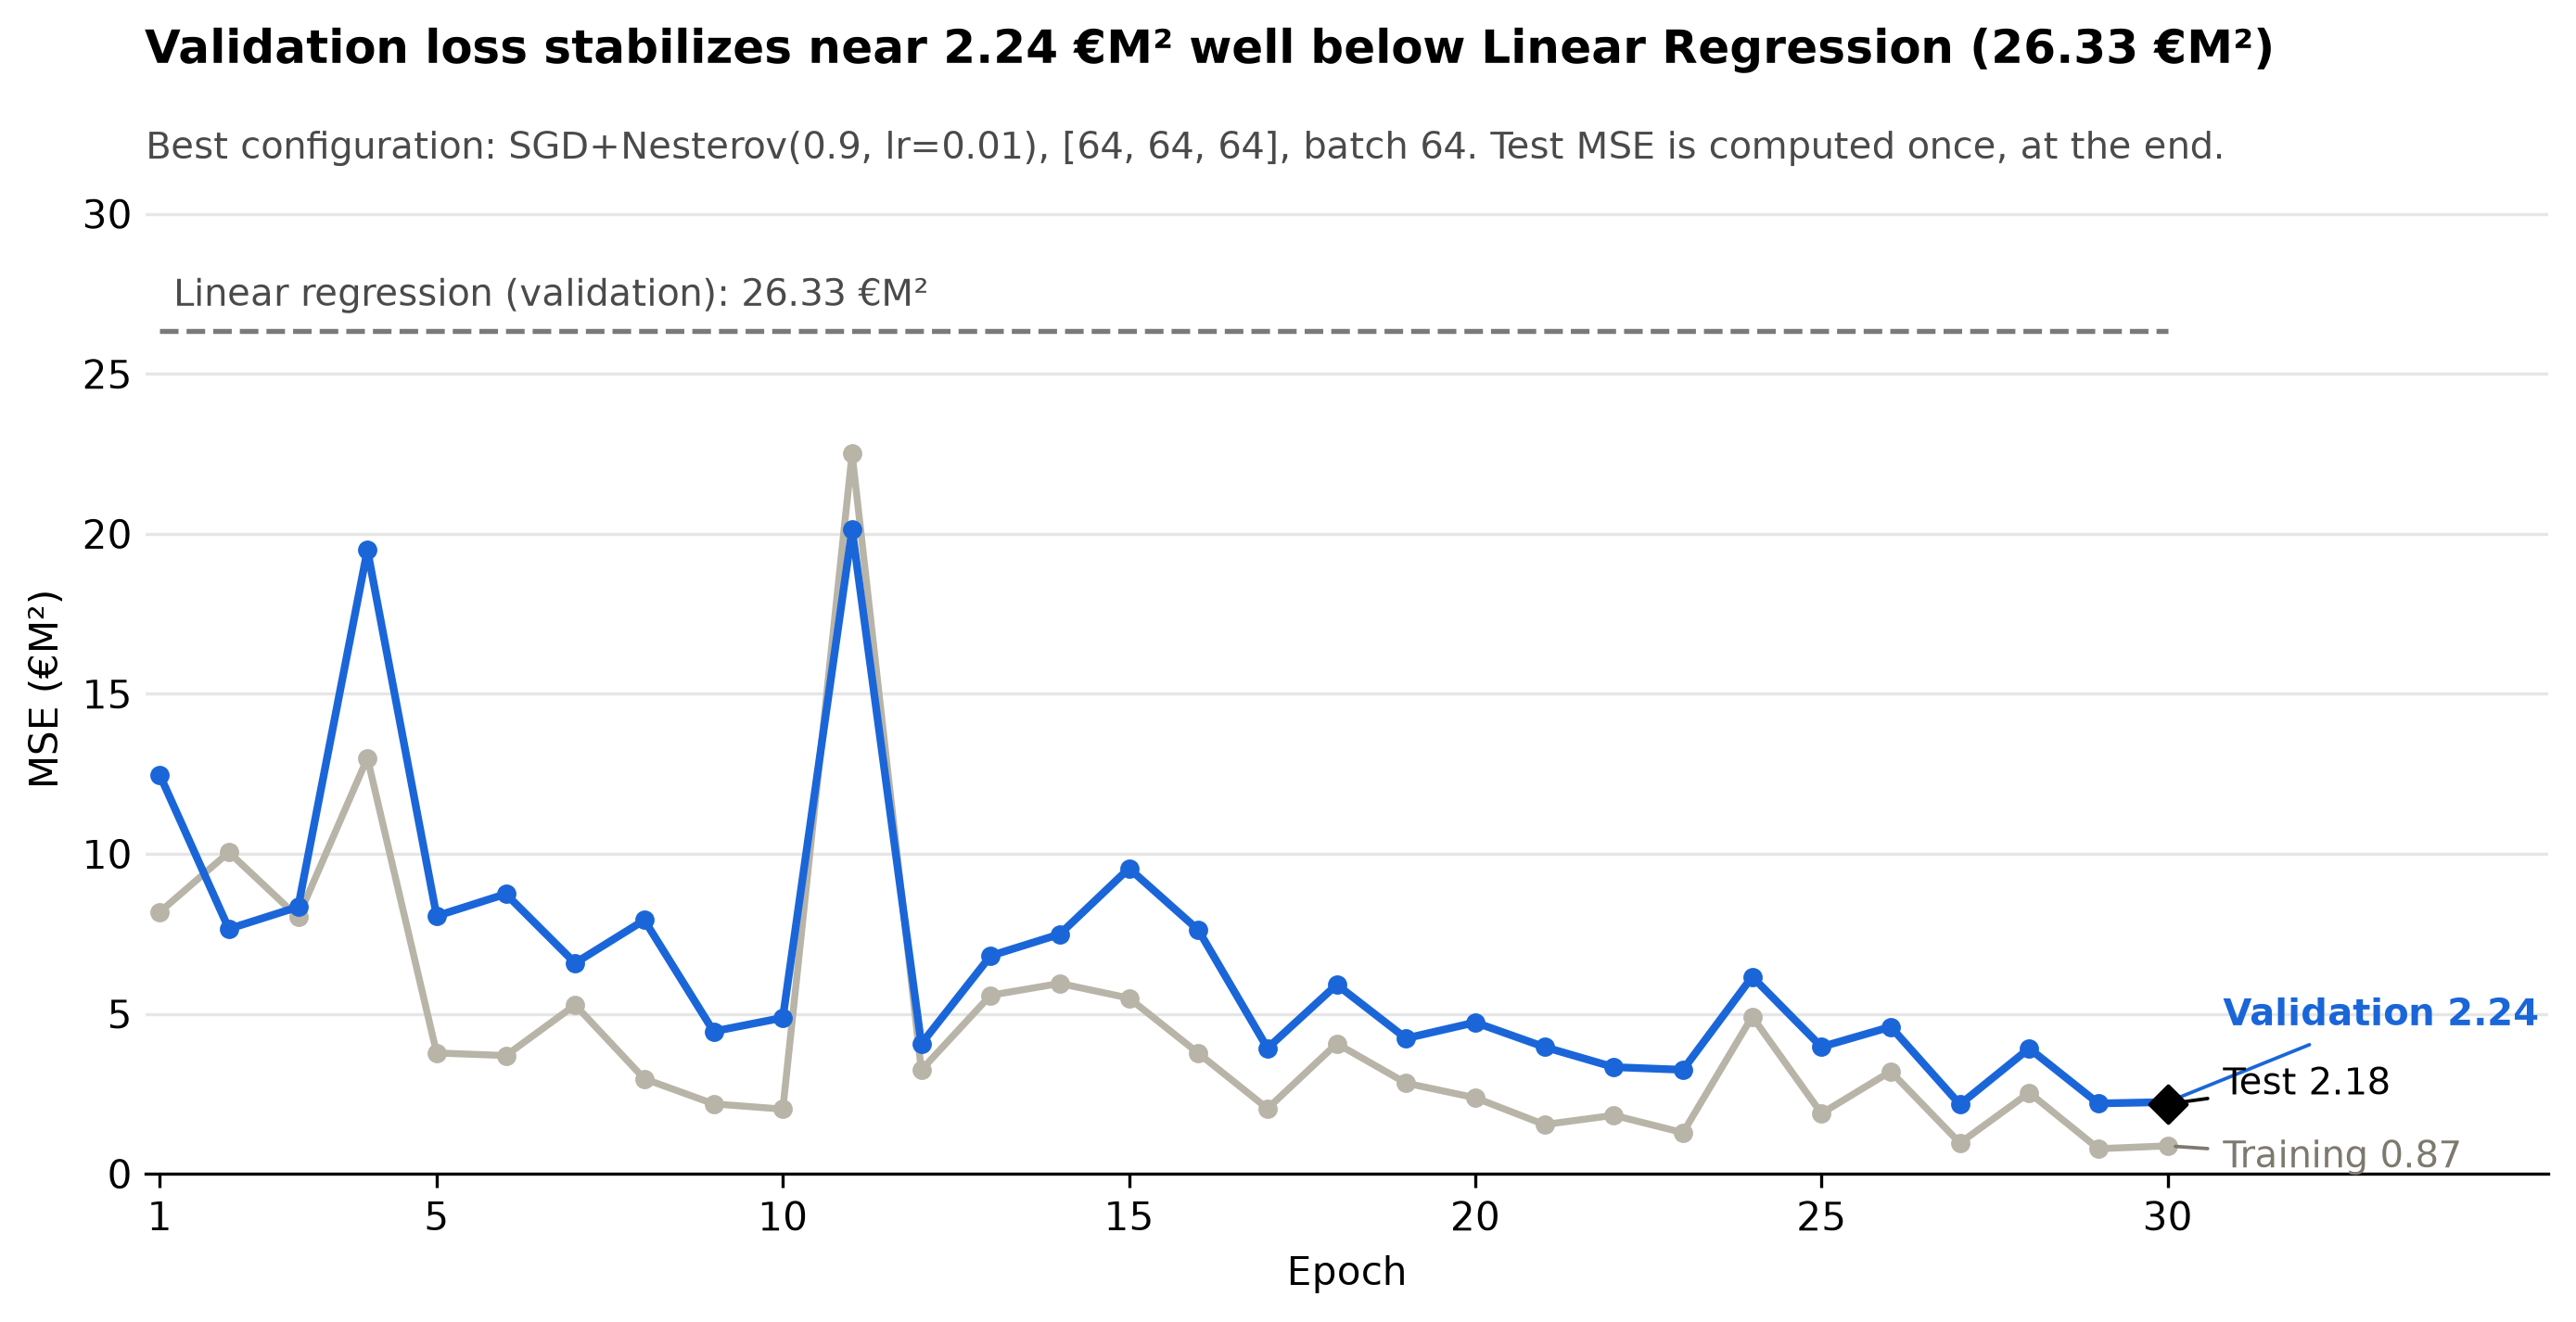

In [42]:
fig, ax = plt.subplots(figsize=(9.5, 4.8), dpi=300)

ax.plot(epochs, train_mse_hist, color="#b8b4a8", marker="o", markersize=4, linewidth=1.8)
ax.plot(epochs, val_mse_hist, color="#1a66d9", marker="o", markersize=4, linewidth=2.0)

ax.hlines(lin_val_mse, xmin=1, xmax=30, colors="#7a7a7a", linestyles="--", linewidth=1.3)
ax.text(1.2, lin_val_mse + 0.8, f"Linear regression (validation): {lin_val_mse:.2f} €M²",
        color="#4a4a4a", fontsize=9.5)

ax.scatter([30], [champ_test_mse], color="black", marker="D", s=45, zorder=5)

ax.annotate(f"Validation {final_val_mse:.2f}", xy=(30, final_val_mse),
            xytext=(30.8, final_val_mse + 2.4), fontsize=9.5, fontweight="bold", color="#1a66d9",
            arrowprops=dict(arrowstyle="-", color="#1a66d9", lw=0.9))

ax.annotate(f"Test {champ_test_mse:.2f}", xy=(30, champ_test_mse),
            xytext=(30.8, champ_test_mse + 0.3), fontsize=9.5, color="black",
            arrowprops=dict(arrowstyle="-", color="black", lw=0.9))
ax.annotate(f"Training {final_train_mse:.2f}", xy=(30, final_train_mse),
            xytext=(30.8, max(0.2, final_train_mse - 1.8)), fontsize=9.5, color="#7d796e",
            arrowprops=dict(arrowstyle="-", color="#7d796e", lw=0.9))

fig.suptitle(f"Validation loss stabilizes near {final_val_mse:.2f} €M² well below Linear Regression ({lin_val_mse:.2f} €M²)",
             x=0.06, ha="left", fontsize=12, fontweight="bold", y=0.98)
ax.set_title(f"Best configuration: {best_row['Run']}, {best_row['Architecture']}, batch {best_row['Batch_Size']}. Test MSE is computed once, at the end.",
             loc="left", fontsize=9.5, color="#4a4a4a", pad=12)

ax.set_xlabel("Epoch", fontsize=10)
ax.set_ylabel("MSE (€M²)", fontsize=10)
ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
ax.set_xlim(0.8, 35.5)
ax.set_ylim(0, max(lin_val_mse, max(val_mse_hist)) * 1.15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.savefig("learning_curve_project_style.png", dpi=300, bbox_inches="tight")
plt.show()